# Corridas, artefactos y modelo de P2 en MLflow — MiBici

**Proyecto:** TC5061 · Equipo 52 · Pregunta P2 (clasificación) · Semana 6  
**Autor:** Roberto Robles · **Rama:** `feature/p2-mlflow-experimentos`  
**Antecedentes:** `2.1-rr-p2-particion-validacion.ipynb` (referencia de la partición y del baseline) y `equipo52_module/modeling/train_p2.py`.

**Propósito.** Comparar lo que registraron las corridas oficiales de P2 (`mlflow run`) contra la referencia de los notebooks: el baseline debe dar las mismas cifras del notebook 2.1 (las mismas filas por conjunto y un F1 de fallas de 0.442 en validación y 0.405 en prueba); si no coinciden, hay un error en la ejecución. Si coinciden, se revisa que cada corrida tenga lo que pide la actividad: etiquetas, artefactos en `plots/`, `data/` y `config/`, versión de los datos (`log_input`) y modelo con firma. Con esa información se arma la tabla comparativa contra el baseline (Tabla 2 del reporte).

**Requisito.** Tener encendido el servidor de MLflow (`mlflow server --backend-store-uri sqlite:///mlflow.db --host 127.0.0.1 --port 5000`) con las corridas oficiales de P2: baseline, búsqueda con nested runs y candidatas. El notebook solo **lee**; no crea corridas.

In [1]:
# Objetivo: conectarse al mismo servidor y experimento que usa train_p2.py.
# Resultado esperado: la dirección del servidor y el id del experimento mibici-equipo52.

import sys
from pathlib import Path

import mlflow
import pandas as pd
from IPython.display import Image, display

sys.path.insert(0, str(Path.cwd().parent))
from equipo52_module.config import MLFLOW_EXPERIMENT, MLFLOW_TRACKING_URI

mlflow.set_tracking_uri(MLFLOW_TRACKING_URI)
cliente = mlflow.MlflowClient()
experimento = cliente.get_experiment_by_name(MLFLOW_EXPERIMENT)
print("Servidor:", MLFLOW_TRACKING_URI, "· experimento:", experimento.name, "· id:", experimento.experiment_id)

/Users/Roberto/Proyectos/equipo52_proyecto_mibici/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
2026-10-24 16:33:19.383 | INFO     | equipo52_module.config:<module>:12 - PROJ_ROOT path is: /Users/Roberto/Proyectos/equipo52_proyecto_mibici


Servidor: http://127.0.0.1:5000 · experimento: mibici-equipo52 · id: 1


## 0. ¿Coincide la corrida oficial con la referencia?

Antes de analizar nada, la corrida oficial del baseline (`p2-base-completo`, lanzada con `mlflow run`) debe registrar exactamente las cifras de referencia del notebook 2.1. Las filas deben ser idénticas y las métricas iguales a tres decimales. Si alguna no coincide, hay un error en la ejecución y no se sigue con el análisis.

In [2]:
# Objetivo: comparar la corrida oficial del baseline contra las cifras de referencia del notebook 2.1.
# Resultado esperado: las 6 filas con "Coincide ✅".

REFERENCIA_21 = {  # tabla «Cifras de referencia para las corridas oficiales» del notebook 2.1
    ("parámetro", "filas_entrenamiento"): 24_566_877,
    ("parámetro", "filas_validacion"): 1_618_000,
    ("parámetro", "filas_entrenamiento_final"): 26_185_615,
    ("parámetro", "filas_prueba"): 1_842_173,
    ("métrica", "val_f1_fallas"): 0.442,
    ("métrica", "test_f1_fallas"): 0.405,
}
base_oficial = mlflow.search_runs(
    [experimento.experiment_id],
    filter_string=("tags.question = 'p2' and tags.stage_of_work = 'baseline' and "
                   "tags.`mlflow.source.type` = 'PROJECT' and attributes.status = 'FINISHED'"),
    order_by=["attributes.start_time DESC"], output_format="list")[0]
print("Corrida oficial:", base_oficial.data.tags["mlflow.runName"], "·", base_oficial.info.run_id)

filas = []
for (tipo, nombre), referencia in REFERENCIA_21.items():
    origen = base_oficial.data.params if tipo == "parámetro" else base_oficial.data.metrics
    registrado = float(origen[nombre])
    coincide = int(registrado) == referencia if tipo == "parámetro" else round(registrado, 3) == referencia
    filas.append({"tipo": tipo, "nombre": nombre, "referencia 2.1": referencia, "corrida oficial": registrado,
                  "resultado": "Coincide ✅" if coincide else "NO coincide ❌"})
comprobacion = pd.DataFrame(filas)
display(comprobacion)
print("Todo coincide: se puede seguir con el análisis." if (comprobacion["resultado"] == "Coincide ✅").all()
      else "Hay diferencias: revisar la ejecución antes de seguir.")

Corrida oficial: p2-base-completo · 935914fde71746ddb22bbb7a228500e4


,tipo,nombre,referencia 2.1,corrida oficial,resultado
0,parámetro,filas_entrenamiento,2.456688e+07,2.456688e+07,Coincide ✅
1,parámetro,filas_validacion,1.618000e+06,1.618000e+06,Coincide ✅
2,parámetro,filas_entrenamiento_final,2.618562e+07,2.618562e+07,Coincide ✅
3,parámetro,filas_prueba,1.842173e+06,1.842173e+06,Coincide ✅
4,métrica,val_f1_fallas,4.420000e-01,4.417144e-01,Coincide ✅
5,métrica,test_f1_fallas,4.050000e-01,4.045255e-01,Coincide ✅


Todo coincide: se puede seguir con el análisis.


## 1. Buscar las corridas de P2 con las etiquetas

Las etiquetas `question`, `model_family` y `stage_of_work` sirven para filtrar. La misma expresión funciona en la caja de búsqueda de la interfaz de MLflow.

In [3]:
# Objetivo: traer las corridas de P2 terminadas y ver sus etiquetas principales.
# Resultado esperado: una fila por corrida, con su etapa (baseline, search o candidate).

corridas = mlflow.search_runs([experimento.experiment_id],
                              filter_string="tags.question = 'p2' and attributes.status = 'FINISHED'",
                              order_by=["attributes.start_time DESC"])
corridas[["tags.mlflow.runName", "tags.stage_of_work", "tags.model_family", "params.periodo",
          "params.peso_fallas", "metrics.val_f1_fallas", "metrics.test_f1_fallas", "start_time"]]

,tags.mlflow.runName,tags.stage_of_work,tags.model_family,params.periodo,params.peso_fallas,metrics.val_f1_fallas,metrics.test_f1_fallas,start_time
0,p2-hgb-postcovid-peso_fallas3,candidate,hgb,postcovid,3,0.480245,0.443890,2026-10-24 21:04:14.301000+00:00
1,p2-logistica-completo-peso_fallas3,candidate,logistica,completo,3,0.427453,0.388018,2026-10-24 20:52:15.208000+00:00
2,p2-hgb-completo-peso_fallas3,candidate,hgb,completo,3,0.482650,0.448581,2026-10-24 18:48:09.264000+00:00
3,p2-busqueda-hgb-completo-peso_fallas8.0-learni...,search,hgb,completo,8.0,0.415040,NaN,2026-10-24 02:39:26.328000+00:00
4,p2-busqueda-hgb-completo-peso_fallas8.0-learni...,search,hgb,completo,8.0,0.412782,NaN,2026-10-24 02:35:00.211000+00:00
5,p2-busqueda-hgb-completo-peso_fallas5.0-learni...,search,hgb,completo,5.0,0.456606,NaN,2026-10-24 02:31:05.974000+00:00
6,p2-busqueda-hgb-completo-peso_fallas5.0-learni...,search,hgb,completo,5.0,0.453768,NaN,2026-10-24 02:26:26.598000+00:00
7,p2-busqueda-hgb-completo-peso_fallas3.0-learni...,search,hgb,completo,3.0,0.482650,NaN,2026-10-24 02:22:28.817000+00:00
8,p2-busqueda-hgb-completo-peso_fallas3.0-learni...,search,hgb,completo,3.0,0.478300,NaN,2026-10-24 02:17:58.135000+00:00
9,p2-busqueda-hgb-completo-peso_fallas2.0-learni...,search,hgb,completo,2.0,0.471572,NaN,2026-10-24 02:14:36.477000+00:00


## 2. Tabla comparativa contra el baseline

Es la base de la **Tabla 2** del reporte: métrica principal en validación y prueba, otras métricas y la mejora contra el baseline (F1 de fallas en prueba de `p2-base-completo`).

In [4]:
# Objetivo: armar la tabla comparativa y calcular la mejora de cada corrida contra el baseline.
# Resultado esperado: el baseline con mejora 0 y cada candidato con su diferencia en puntos y en %.

base = corridas[corridas["tags.stage_of_work"] == "baseline"].iloc[0]
f1_base = base["metrics.test_f1_fallas"]
tabla = pd.DataFrame({
    "corrida": corridas["tags.mlflow.runName"],
    "etapa": corridas["tags.stage_of_work"],
    "familia": corridas["tags.model_family"],
    "periodo": corridas["params.periodo"],
    "peso_fallas": corridas.get("params.peso_fallas"),
    "learning_rate (hgb)": corridas.get("params.hgb_learning_rate"),
    "C (logística)": corridas.get("params.logistica_C"),
    "val F1 fallas": corridas["metrics.val_f1_fallas"].round(3),
    "test F1 fallas": corridas["metrics.test_f1_fallas"].round(3),
    "test recall sin bicicletas": corridas["metrics.test_recall_sin_bicicletas"].round(3),
    "test recall sin anclajes": corridas["metrics.test_recall_sin_anclajes"].round(3),
    "mejora (puntos)": (corridas["metrics.test_f1_fallas"] - f1_base).round(3),
    "mejora (%)": ((corridas["metrics.test_f1_fallas"] / f1_base - 1) * 100).round(1),
})
tabla

,corrida,etapa,familia,periodo,peso_fallas,learning_rate (hgb),C (logística),val F1 fallas,test F1 fallas,test recall sin bicicletas,test recall sin anclajes,mejora (puntos),mejora (%)
0,p2-hgb-postcovid-peso_fallas3,candidate,hgb,postcovid,3,0.1,NaN,0.480,0.444,0.496,0.534,0.039,9.7
1,p2-logistica-completo-peso_fallas3,candidate,logistica,completo,3,NaN,1.0,0.427,0.388,0.317,0.405,-0.017,-4.1
2,p2-hgb-completo-peso_fallas3,candidate,hgb,completo,3,0.1,NaN,0.483,0.449,0.481,0.537,0.044,10.9
3,p2-busqueda-hgb-completo-peso_fallas8.0-learni...,search,hgb,completo,8.0,0.1,NaN,0.415,NaN,NaN,NaN,NaN,NaN
4,p2-busqueda-hgb-completo-peso_fallas8.0-learni...,search,hgb,completo,8.0,0.05,NaN,0.413,NaN,NaN,NaN,NaN,NaN
5,p2-busqueda-hgb-completo-peso_fallas5.0-learni...,search,hgb,completo,5.0,0.1,NaN,0.457,NaN,NaN,NaN,NaN,NaN
6,p2-busqueda-hgb-completo-peso_fallas5.0-learni...,search,hgb,completo,5.0,0.05,NaN,0.454,NaN,NaN,NaN,NaN,NaN
7,p2-busqueda-hgb-completo-peso_fallas3.0-learni...,search,hgb,completo,3.0,0.1,NaN,0.483,NaN,NaN,NaN,NaN,NaN
8,p2-busqueda-hgb-completo-peso_fallas3.0-learni...,search,hgb,completo,3.0,0.05,NaN,0.478,NaN,NaN,NaN,NaN,NaN
9,p2-busqueda-hgb-completo-peso_fallas2.0-learni...,search,hgb,completo,2.0,0.1,NaN,0.472,NaN,NaN,NaN,NaN,NaN


## 3. Artefactos de una corrida candidata

El modelo no aparece en esta lista: MLflow 3 lo guarda como "Logged model" de la corrida y se carga en la sección 5.

In [6]:
# Objetivo: listar todos los artefactos de la corrida candidata más reciente.
# Resultado esperado: archivos en plots/, data/, config/ y modelo/.

candidata = corridas[corridas["tags.stage_of_work"] == "candidate"].iloc[0]
id_corrida = candidata["run_id"]
print("Corrida:", candidata["tags.mlflow.runName"], "·", id_corrida)


def listar(ruta=""):
    for archivo in cliente.list_artifacts(id_corrida, ruta):
        if archivo.is_dir:
            listar(archivo.path)
        else:
            print(f"  {archivo.path}  ({archivo.file_size:,} bytes)")


listar()

Corrida: p2-hgb-postcovid-peso_fallas3 · be8172dd139d45d2ba201ee23c9eeb1c
  config/MLproject  (1,320 bytes)
  config/config.py  (2,807 bytes)
  config/corrida_p2.json  (1,915 bytes)
  config/python_env.yaml  (112 bytes)
  data/manifiesto_datos.csv  (24,108 bytes)
  data/p2_porcentaje_clases_por_anio.csv  (313 bytes)
  data/p2_tabla_confusion_prueba.csv  (127 bytes)
  plots/p2_matriz_confusion_prueba.png  (51,670 bytes)
  plots/p2_precision_recall_prueba.png  (71,482 bytes)


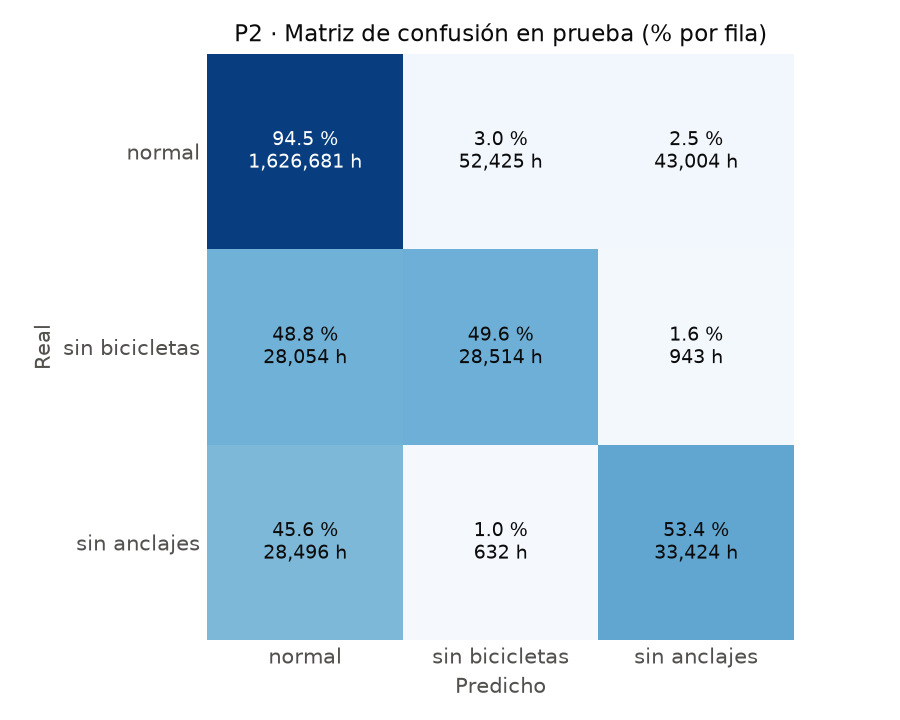

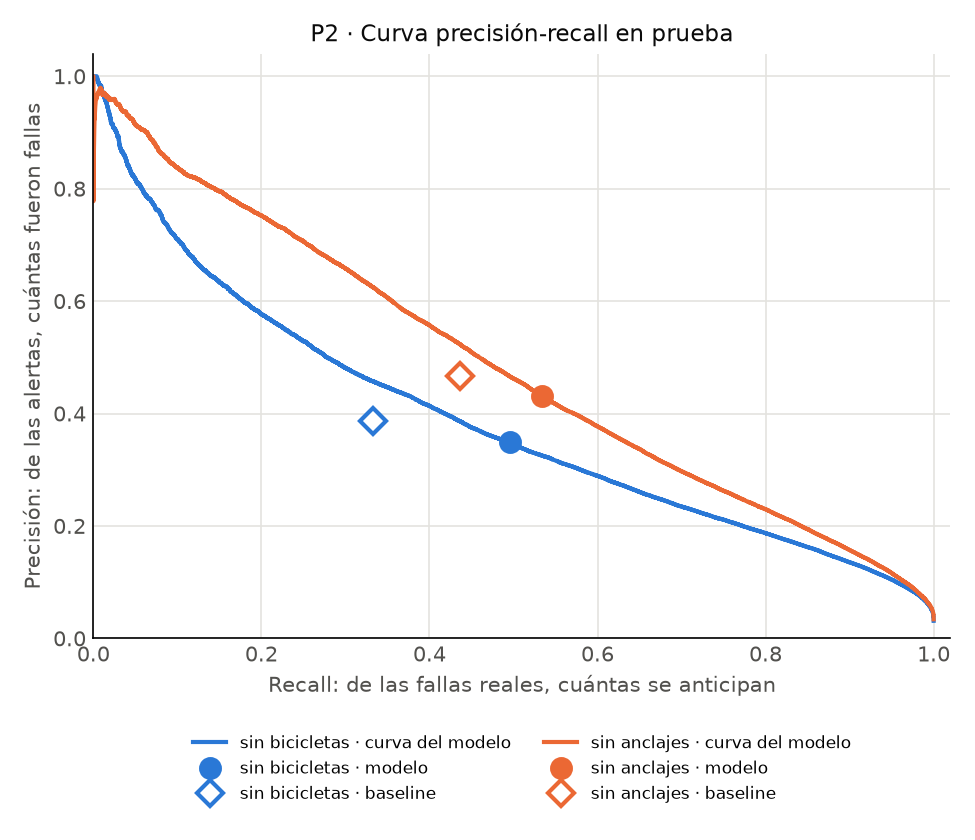

In [7]:
# Objetivo: ver las dos gráficas de la corrida candidata.
# Resultado esperado: la matriz de confusión y la curva precisión-recall con el punto del modelo y del baseline.

for grafica in ["plots/p2_matriz_confusion_prueba.png", "plots/p2_precision_recall_prueba.png"]:
    display(Image(mlflow.artifacts.download_artifacts(run_id=id_corrida, artifact_path=grafica)))

## 4. Versión de los datos: `log_input`

En la sección *Datasets* de la corrida aparecen los conjuntos de entrenamiento y prueba. MLflow guarda su **descripción** (nombre, huella, origen, esquema y número de filas), no los datos.

In [8]:
# Objetivo: leer los conjuntos registrados en la corrida.
# Resultado esperado: p2-entrenamiento-completo (training) y p2-prueba (testing), con su huella y número de filas.

for entrada in cliente.get_run(id_corrida).inputs.dataset_inputs:
    contexto = [t.value for t in entrada.tags if t.key == "mlflow.data.context"]
    print(entrada.dataset.name, contexto, "· huella", entrada.dataset.digest, "·", entrada.dataset.profile)

p2-entrenamiento-postcovid ['training'] · huella b4992d0a · {"num_rows": 8959353, "num_elements": 125430942}
p2-prueba ['testing'] · huella 575fc82f · {"num_rows": 1842173, "num_elements": 25790422}


## 5. El modelo y su firma

La **firma** dice qué columnas y tipos recibe el modelo y qué devuelve. Si alguien le pasa columnas distintas, MLflow lo detiene antes de predecir.

In [9]:
# Objetivo: cargar el modelo de la corrida y revisar su firma y su ejemplo de entrada.
# Resultado esperado: 13 variables de entrada y la clase predicha (0 normal, 1 sin bicicletas, 2 sin anclajes).

modelo = mlflow.pyfunc.load_model(f"runs:/{id_corrida}/modelo")
print(modelo.metadata.signature)
ejemplo = modelo.input_example
display(ejemplo)
print("Predicción para el ejemplo:", modelo.predict(ejemplo))

inputs: 
  ['hora_del_dia': integer (required), 'dia_semana': integer (required), 'mes': integer (required), 'fin_de_semana': integer (required), 'capacidad': long (required), 'latitud': double (required), 'longitud': double (required), 'salidas_hora_anterior': float (required), 'llegadas_hora_anterior': float (required), 'salidas_3_horas_anteriores': float (required), 'llegadas_3_horas_anteriores': float (required), 'semanas_sin_bicicletas': float (required), 'semanas_sin_anclajes': float (required)]
outputs: 
  [Tensor('int64', (-1,))]
params: 
  None



,hora_del_dia,dia_semana,mes,fin_de_semana,capacidad,latitud,longitud,salidas_hora_anterior,llegadas_hora_anterior,salidas_3_horas_anteriores,llegadas_3_horas_anteriores,semanas_sin_bicicletas,semanas_sin_anclajes
0,0,2,4,0,15,20.666378,-103.34882,0.0,0.0,1.0,2.0,0.0,0.0
1,1,2,4,0,15,20.666378,-103.34882,0.0,0.0,0.0,1.0,0.0,0.0
2,2,2,4,0,15,20.666378,-103.34882,0.0,0.0,0.0,0.0,0.0,0.0
3,3,2,4,0,15,20.666378,-103.34882,0.0,0.0,0.0,0.0,0.0,0.0
4,4,2,4,0,15,20.666378,-103.34882,0.0,0.0,0.0,0.0,0.0,0.0


Predicción para el ejemplo: [0 0 0 0 0]


## 6. Interpretar la regresión logística

La regresión logística guarda sus coeficientes en `data/p2_coeficientes_logistica.csv`. Como las variables están estandarizadas, el tamaño de cada coeficiente indica cuánto empuja esa variable hacia cada clase: positivo la hace más probable, negativo menos. Las columnas `missingindicator_…` marcan las horas sin historial. HGB es más potente, pero no se puede leer así; esa diferencia sirve para el criterio de costo e interpretabilidad del reporte (Treveil et al., 2020, Tabla 4-2).

In [10]:
# Objetivo: leer los coeficientes de la corrida logística más reciente, si ya existe.
# Resultado esperado: una fila por variable y una columna por clase, ordenadas por su peso hacia "sin bicicletas".

logisticas = corridas[corridas["tags.model_family"] == "logistica"]
if logisticas.empty:
    print("Todavía no hay corridas de regresión logística.")
else:
    ruta = mlflow.artifacts.download_artifacts(run_id=logisticas.iloc[0]["run_id"],
                                               artifact_path="data/p2_coeficientes_logistica.csv")
    coeficientes = pd.read_csv(ruta, index_col="variable")
    display(coeficientes.sort_values("sin_bicicletas", key=abs, ascending=False))

,normal,sin_bicicletas,sin_anclajes
variable,,,
semanas_sin_bicicletas,-0.2929,0.5995,-0.4354
semanas_sin_anclajes,-0.2831,-0.4396,0.5641
llegadas_hora_anterior,-0.1603,0.1673,0.0390
longitud,-0.0940,-0.1381,0.2261
capacidad,0.1957,-0.1098,-0.0852
latitud,-0.0414,-0.0985,0.1411
fin_de_semana,0.1092,-0.0633,-0.0501
salidas_hora_anterior,-0.1228,0.0284,0.1501
salidas_3_horas_anteriores,-0.0308,0.0228,0.0262


## 7. Próximos pasos

- **Paso F · búsqueda con nested runs:** una corrida padre con `stage_of_work = search` y una hija por combinación de hiperparámetros. Aquí agregaremos cómo leer el árbol padre-hijas.
- **Paso G · Model Registry:** registrar el modelo elegido como `mibici-equipo52-p2-riesgo` con alias `champion` y cargarlo con `models:/mibici-equipo52-p2-riesgo@champion`.